# Standard Grover Search Validation

## Research question

**Does the implementation reproduce the theoretical Grover success dynamics for different search space sizes $N$, marked counts $s$, and Grover iteration counts $t$?**

This notebook establishes the mathematical and computational baseline for the later study of Grover search when the number of marked states is unknown.

The purpose here is not merely to obtain a high success probability. The purpose is to test whether the implemented oracle and diffusion operator reproduce the complete theoretical trajectory predicted by Grover search.

The later unknown $s$ problem depends on this baseline being trustworthy.

## 1. Mathematical model

Let the search space contain

$$
N = 2^n
$$

computational basis states, of which exactly $s$ are marked.

Throughout the nontrivial Grover analysis in this notebook,

$$
1\le s<N.
$$

The case $s=N$ is trivial because every basis state is marked and the initial uniform state already succeeds with probability one. It is excluded so that both the marked and unmarked normalized states below are well defined.

Let $A$ denote the set of marked states. Define the normalized uniform superposition over the marked subspace by

$$
|A_1\rangle
=
\frac{1}{\sqrt{s}}
\sum_{x\in A}|x\rangle,
$$

and the normalized uniform superposition over the unmarked subspace by

$$
|A_0\rangle
=
\frac{1}{\sqrt{N-s}}
\sum_{x\notin A}|x\rangle.
$$

The usual uniform initial state is

$$
|u\rangle
=
\frac{1}{\sqrt N}
\sum_{x=0}^{N-1}|x\rangle.
$$

Grouping the marked and unmarked amplitudes gives

$$
|u\rangle
=
\sqrt{\frac{N-s}{N}}\,|A_0\rangle
+
\sqrt{\frac{s}{N}}\,|A_1\rangle.
$$

Introduce an angle $\theta$ such that

$$
\sin^2\theta = \frac{s}{N},
\qquad
\theta = \arcsin\sqrt{\frac{s}{N}}.
$$

Then

$$
|u\rangle
=
\cos\theta\,|A_0\rangle
+
\sin\theta\,|A_1\rangle.
$$

This reduces the relevant Grover dynamics to the two dimensional subspace spanned by $|A_0\rangle$ and $|A_1\rangle$.

### 1.1 One Grover iteration

A Grover iteration consists of two reflections.

The phase oracle changes the sign of every marked basis state:

$$
Z_f|x\rangle
=
(-1)^{f(x)}|x\rangle.
$$

The diffusion operator reflects the state about the uniform superposition:

$$
D = 2|u\rangle\langle u| - I.
$$

The Grover operator is therefore

$$
G = D Z_f.
$$

Within the two dimensional search subspace, the composition of these reflections is a rotation by

$$
2\theta.
$$

The initial state begins at angle $\theta$ from the unmarked direction. After $t$ Grover iterations,

$$
G^t|u\rangle
=
\cos((2t+1)\theta)|A_0\rangle
+
\sin((2t+1)\theta)|A_1\rangle.
$$


### 1.2 Theoretical success probability

The probability of measuring any marked state after $t$ Grover iterations is therefore

$$
\boxed{
P_{\mathrm{theory}}(t)
=
\sin^2((2t+1)\theta)
}
$$

where

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}.
$$

The multiple solution Grover trajectory, including the relation $\sin^2\theta=s/N$ and the resulting oscillatory success probability, is established in Boyer et al. [2]. The same sinusoidal dynamics appears in the general amplitude amplification framework of Brassard et al. [3].

The ideal continuous first maximum occurs when

$$
(2t+1)\theta
=
\frac{\pi}{2},
$$

which gives

$$
t_{\mathrm{continuous}}
=
\frac{\pi}{4\theta}
-
\frac{1}{2}.
$$

Because the actual iteration count must be an integer, the best integer iteration count is one of the nearby integers. We will evaluate the neighboring candidates directly rather than assume that a particular rounding rule is always optimal.

For $s/N\ll 1$,

$$
\theta \approx \sqrt{\frac{s}{N}},
$$

so the useful iteration scale is

$$
t = O\left(\sqrt{\frac{N}{s}}\right).
$$

This dependence on $s$ is the reason the unknown solution count problem eventually appears.


## 2. Implementation setup

The validation code below keeps the experimental state explicit and reproducible.

For each pair $(n,s)$:

1. Exactly $s$ distinct computational basis states are marked.
2. The theoretical probability is computed from the closed form expression.
3. The simulated probability is obtained from the Grover statevector implementation.
4. The two values are compared at identical iteration counts.

The identities of the marked basis states are chosen deterministically for this validation. This removes unnecessary sampling variability. In ideal Grover search, the total success probability depends on the number of marked states, not on their particular binary labels.

### 2.1 Imports

In [1]:
from math import asin, sqrt, sin, pi, floor, ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Qiskit 2.x uses DiagonalGate. Older Qiskit releases used Diagonal.
try:
    from qiskit.circuit.library import DiagonalGate
except ImportError:
    from qiskit.circuit.library import Diagonal as DiagonalGate

print("Qiskit version:", qiskit.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Qiskit version: 2.3.0
NumPy version: 2.4.2
Pandas version: 3.0.0


### 2.2 Implementation scope

A minimal self contained Grover implementation is used so that the validation procedure is reproducible and the mathematical model can be compared directly with the simulated circuit dynamics.

### 2.3 Deterministic marked state construction

For validation, exactly $s$ computational basis states are marked:

$$
|\mathcal{M}| = s.
$$

The first $s$ basis states are chosen only to make every run reproducible.

For ideal Grover dynamics, the total probability of landing in the marked subspace depends on the number of marked states $s$, not on their particular binary labels.

In [2]:
def make_marked_states(n: int, s: int):
    """Return exactly s distinct n-bit computational basis states."""
    if not isinstance(n, (int, np.integer)) or isinstance(n, bool):
        raise TypeError("n must be an integer")

    if n < 1:
        raise ValueError("n must be at least 1")

    N = 2 ** int(n)

    if not isinstance(s, (int, np.integer)) or isinstance(s, bool):
        raise TypeError("s must be an integer")

    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < 2**n")

    marked = [
        format(i, f"0{n}b")
        for i in range(int(s))
    ]

    assert len(marked) == s
    assert len(set(marked)) == s
    assert all(len(x) == n for x in marked)

    return marked

### 2.4 Phase oracle

For a marked set $\mathcal{M}$, the phase oracle acts as

$$
Z_f|x\rangle
=
(-1)^{f(x)}|x\rangle,
$$

where

$$
f(x)
=
\begin{cases}
1, & x\in\mathcal{M},\\
0, & x\notin\mathcal{M}.
\end{cases}
$$

For this small statevector validation study, the oracle is represented explicitly as a diagonal unitary.

This is convenient for validating Grover dynamics, but it is **not** being claimed as a scalable oracle construction for arbitrary search problems.

In [3]:
def build_phase_oracle(n: int, marked):
    """Construct an explicit diagonal phase oracle for validation."""
    N = 2 ** n
    phases = np.ones(N, dtype=complex)

    for bitstring in marked:
        if len(bitstring) != n or any(bit not in "01" for bit in bitstring):
            raise ValueError(f"Invalid marked bitstring: {bitstring}")

        phases[int(bitstring, 2)] = -1.0

    return DiagonalGate(phases.tolist())

### 2.5 Diffusion operator

The standard diffusion operator is

$$
D
=
2|u\rangle\langle u| - I.
$$

A circuit implementation can be written, up to an irrelevant global phase, as

$$
H^{\otimes n}
X^{\otimes n}
CZ_{\mathrm{multi}}
X^{\otimes n}
H^{\otimes n}.
$$

Global phase does not affect measurement probabilities, so either sign convention for the reflection produces the same success probabilities when used consistently.

In [4]:
def apply_zero_state_phase_flip(circuit: QuantumCircuit, qubits):
    """
    Apply a phase flip to |0...0>.
    The result differs from the conventional diffusion reflection
    by at most a global phase, which does not affect probabilities.
    """
    qubits = list(qubits)

    if len(qubits) == 1:
        q = qubits[0]
        circuit.x(q)
        circuit.z(q)
        circuit.x(q)
        return

    for q in qubits:
        circuit.x(q)

    controls = qubits[:-1]
    target = qubits[-1]

    circuit.h(target)
    circuit.mcx(controls, target)
    circuit.h(target)

    for q in qubits:
        circuit.x(q)


def apply_diffusion(circuit: QuantumCircuit, qubits):
    qubits = list(qubits)

    for q in qubits:
        circuit.h(q)

    apply_zero_state_phase_flip(circuit, qubits)

    for q in qubits:
        circuit.h(q)

### 2.6 Grover circuit and statevector simulation

The circuit begins in

$$
|0\rangle^{\otimes n}
$$

and applies

$$
H^{\otimes n}
$$

to prepare the uniform state.

Each Grover iteration then applies

$$
Z_f
$$

followed by the diffusion operator.

Grover iteration count is a discrete quantity. The implementation therefore requires

$$
t\in\mathbb Z_{\ge0}
$$

and rejects noninteger values rather than silently truncating them.

In [5]:
def validate_iteration_count(t):
    """Return t as int after validating t is a nonnegative integer."""
    if not isinstance(t, (int, np.integer)) or isinstance(t, bool):
        raise TypeError("t must be a nonnegative integer")

    t = int(t)

    if t < 0:
        raise ValueError("t must be nonnegative")

    return t


def build_grover_circuit(n: int, marked, t: int) -> QuantumCircuit:
    """Build an ideal Grover circuit with exactly t iterations."""
    t = validate_iteration_count(t)

    qc = QuantumCircuit(n)
    qc.h(range(n))

    oracle = build_phase_oracle(n, marked)

    for _ in range(t):
        qc.append(oracle, range(n))
        apply_diffusion(qc, range(n))

    return qc


def simulation_success_probability(n: int, marked, t: int) -> float:
    """Exact statevector probability of measuring a marked state."""
    t = validate_iteration_count(t)

    qc = build_grover_circuit(n, marked, t)
    state = Statevector.from_instruction(qc)
    probabilities = state.probabilities()

    return float(
        sum(probabilities[int(bitstring, 2)] for bitstring in marked)
    )

### 2.7 Theoretical prediction

For

$$
N=2^n
$$

and $s$ marked states,

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}.
$$

The theoretical success probability after $t$ Grover iterations is

$$
P_{\mathrm{theory}}(t)
=
\sin^2((2t+1)\theta).
$$


In [6]:
def grover_theory_probability(N: int, s: int, t: int) -> float:
    """Closed-form ideal Grover success probability for 1 <= s < N."""
    if not isinstance(N, (int, np.integer)) or isinstance(N, bool):
        raise TypeError("N must be an integer")

    if not isinstance(s, (int, np.integer)) or isinstance(s, bool):
        raise TypeError("s must be an integer")

    if N < 2:
        raise ValueError("N must be at least 2")

    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < N")

    t = validate_iteration_count(t)

    theta = asin(sqrt(s / N))
    return sin((2 * t + 1) * theta) ** 2


def theoretical_best_integer_t(N: int, s: int) -> int:
    """
    Compare the two integers nearest the continuous first maximum
    and return the one with the larger theoretical success probability.
    """
    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < N")

    theta = asin(sqrt(s / N))
    t_continuous = pi / (4 * theta) - 0.5

    candidates = {
        max(0, floor(t_continuous)),
        max(0, ceil(t_continuous)),
    }

    return max(
        candidates,
        key=lambda t: grover_theory_probability(N, s, t),
    )

## 3. Single case sanity check

We begin with

$$
n=5,
\qquad
N=32,
\qquad
s=1.
$$

Before performing any broad sweep, theory and simulation are compared for several individual iteration counts.

The aim is to establish whether the implementation follows the expected trajectory in a small transparent case.

In [7]:
n = 5
N = 2 ** n
s = 1

marked = make_marked_states(n, s)

print("n =", n)
print("N =", N)
print("s =", s)
print("marked states =", marked)

assert len(marked) == s

n = 5
N = 32
s = 1
marked states = ['00000']


In [8]:
sanity_rows = []

for t in range(8):
    p_theory = grover_theory_probability(N, s, t)
    p_sim = simulation_success_probability(n, marked, t)

    sanity_rows.append({
        "n": n,
        "N": N,
        "s": s,
        "t": t,
        "P_theory": p_theory,
        "P_sim": p_sim,
        "absolute_error": abs(p_sim - p_theory),
    })

sanity_df = pd.DataFrame(sanity_rows)
sanity_df

,n,N,s,t,P_theory,P_sim,absolute_error
0,5,32,1,0,0.031250,0.031250,3.122502e-17
1,5,32,1,1,0.258301,0.258301,1.720846e-15
2,5,32,1,2,0.602425,0.602425,7.438494e-15
3,5,32,1,3,0.896937,0.896937,1.731948e-14
4,5,32,1,4,0.999182,0.999182,2.464695e-14
5,5,32,1,5,0.859637,0.859637,2.664535e-14
6,5,32,1,6,0.545892,0.545892,1.998401e-14
7,5,32,1,7,0.209918,0.209918,8.965051e-15


### 3.1 Interpreting the sanity check

Under an ideal statevector simulation, substantial disagreement is not expected.

The purpose of this comparison is not to independently establish Grover's theoretical result. It is to verify that the circuit implementation used in this project realizes the corresponding ideal unitary dynamics.

If

$$
P_{\mathrm{sim}}(t)
\not\approx
P_{\mathrm{theory}}(t),
$$

we stop here and ask why.

Possible causes include the phase oracle, diffusion operator, bit ordering, marked state construction, or an inconsistency between the theoretical and implemented value of $s$.

Agreement is not treated as the end of the investigation either. It tells us that this particular implementation realizes the theoretical unitary dynamics closely enough to justify broader validation.


### 3.2 Direct check of marked label independence

The ideal theory predicts that the **total** success probability depends on the number of marked states $s$, not on which computational basis labels are marked.

To test that implementation claim directly, keep

$$
N=256,
\qquad
s=4
$$

fixed and compare several distinct marked sets:

$$
\{0,1,2,3\},
$$

$$
\{7,31,109,220\},
$$

and

$$
\{15,63,127,255\}.
$$

If the oracle indexing and bit ordering are implemented consistently, the three total marked probability trajectories should agree with one another and with the closed form theory to numerical precision.

In [9]:
n_label = 8
N_label = 2 ** n_label
s_label = 4

marked_integer_sets = [
    [0, 1, 2, 3],
    [7, 31, 109, 220],
    [15, 63, 127, 255],
]

marked_label_sets = [
    [
        format(value, f"0{n_label}b")
        for value in integer_set
    ]
    for integer_set in marked_integer_sets
]

label_rows = []

for t in range(11):
    p_theory = grover_theory_probability(
        N_label,
        s_label,
        t,
    )

    simulated = [
        simulation_success_probability(
            n_label,
            marked,
            t,
        )
        for marked in marked_label_sets
    ]

    label_rows.append({
        "t": t,
        "P_theory": p_theory,
        "P_set_1": simulated[0],
        "P_set_2": simulated[1],
        "P_set_3": simulated[2],
        "max_pairwise_spread": (
            max(simulated) - min(simulated)
        ),
        "max_error_vs_theory": max(
            abs(p - p_theory)
            for p in simulated
        ),
    })

label_independence_df = pd.DataFrame(
    label_rows
)

print(
    "Maximum trajectory spread across marked label sets:",
    f"{label_independence_df['max_pairwise_spread'].max():.3e}",
)

print(
    "Maximum error versus theory:",
    f"{label_independence_df['max_error_vs_theory'].max():.3e}",
)

label_independence_df

Maximum trajectory spread across marked label sets: 3.453e-14
Maximum error versus theory: 1.473e-13


,t,P_theory,P_set_1,P_set_2,P_set_3,max_pairwise_spread,max_error_vs_theory
0,0,0.015625,0.015625,0.015625,0.015625,0.000000e+00,2.081668e-17
1,1,0.134827,0.134827,0.134827,0.134827,7.216450e-16,3.219647e-15
2,2,0.343895,0.343895,0.343895,0.343895,2.331468e-15,1.582068e-14
3,3,0.591380,0.591380,0.591380,0.591380,7.549517e-15,4.207745e-14
4,4,0.816377,0.816377,0.816377,0.816377,1.898481e-14,7.727152e-14
5,5,0.963515,0.963515,0.963515,0.963515,2.475797e-14,1.124656e-13
6,6,0.996586,0.996586,0.996586,0.996586,3.452794e-14,1.391109e-13
7,7,0.907449,0.907449,0.907449,0.907449,3.241851e-14,1.473266e-13
8,8,0.718042,0.718042,0.718042,0.718042,3.264056e-14,1.338929e-13
9,9,0.474976,0.474976,0.474976,0.474976,2.564615e-14,1.000311e-13


## 4. Theory versus simulation trajectory

A single successful iteration count is not sufficient evidence.

We compare the complete trajectory across the rise toward the first maximum and the subsequent overshooting region.

In [10]:
t_star = theoretical_best_integer_t(N, s)
t_max = 2 * t_star + 4

trajectory_rows = []

for t in range(t_max + 1):
    p_theory = grover_theory_probability(N, s, t)
    p_sim = simulation_success_probability(n, marked, t)

    trajectory_rows.append({
        "t": t,
        "P_theory": p_theory,
        "P_sim": p_sim,
        "absolute_error": abs(p_sim - p_theory),
    })

trajectory_df = pd.DataFrame(trajectory_rows)

max_abs_error = trajectory_df["absolute_error"].max()
mse = np.mean(
    (trajectory_df["P_sim"] - trajectory_df["P_theory"]) ** 2
)

print("Best integer first-peak t:", t_star)
print("Maximum absolute error:", max_abs_error)
print("MSE:", mse)

trajectory_df

Best integer first-peak t: 4
Maximum absolute error: 6.38378239159465e-14
MSE: 6.333576208090204e-28


,t,P_theory,P_sim,absolute_error
0,0,0.031250,0.031250,3.122502e-17
1,1,0.258301,0.258301,1.720846e-15
2,2,0.602425,0.602425,7.438494e-15
3,3,0.896937,0.896937,1.731948e-14
4,4,0.999182,0.999182,2.464695e-14
5,5,0.859637,0.859637,2.664535e-14
6,6,0.545892,0.545892,1.998401e-14
7,7,0.209918,0.209918,8.965051e-15
8,8,0.014453,0.014453,6.713380e-16
9,9,0.054175,0.054175,2.789435e-15


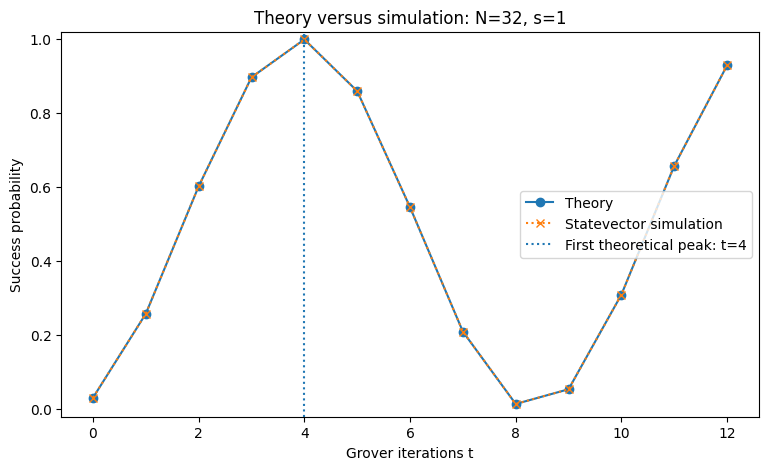

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    trajectory_df["t"],
    trajectory_df["P_theory"],
    marker="o",
    label="Theory",
)

plt.plot(
    trajectory_df["t"],
    trajectory_df["P_sim"],
    marker="x",
    linestyle=":",
    label="Statevector simulation",
)

plt.axvline(
    t_star,
    linestyle=":",
    label=f"First theoretical peak: t={t_star}",
)

plt.xlabel("Grover iterations t")
plt.ylabel("Success probability")
plt.title(f"Theory versus simulation: N={N}, s={s}")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

### 4.1 Quantifying agreement

We record

$$
E_{\max}
=
\max_t
\left|
P_{\mathrm{sim}}(t)-P_{\mathrm{theory}}(t)
\right|
$$

and

$$
\mathrm{MSE}
=
\frac{1}{T+1}
\sum_{t=0}^{T}
\left(
P_{\mathrm{sim}}(t)-P_{\mathrm{theory}}(t)
\right)^2.
$$

The first captures the worst observed disagreement. The second summarizes disagreement across the complete tested trajectory.

## 5. Multiple $N,s$ validation sweep

A single example can agree by accident or because of a case specific implementation detail.

We therefore test

$$
n\in\{5,6,7,8\}
$$

with

$$
s\in\{1,2,4,8\}.
$$

For each pair, theory and simulation are compared across a trajectory extending beyond the first maximum.

The theoretical first peak is computed from the closed form model.

The first simulated local maximum is detected directly from the simulated trajectory rather than being selected from neighboring values around the theoretical prediction. The sampled interval is chosen using the theoretical timescale only to ensure that it extends beyond the first maximum. Theory therefore determines how far the trajectory is sampled, but not which sampled iteration is identified as the simulated first maximum.


In [12]:
def first_local_maximum_t(case_df, probability_column):
    """
    Return the first discrete local maximum in an ordered trajectory.

    A local maximum at t satisfies P(t) >= P(t-1) and P(t) >= P(t+1).
    """
    ordered = (
        case_df
        .sort_values("t")
        .reset_index(drop=True)
    )

    values = ordered[
        probability_column
    ].to_numpy(dtype=float)

    times = ordered[
        "t"
    ].to_numpy(dtype=int)

    if len(values) == 1:
        return int(times[0])

    if values[0] >= values[1]:
        return int(times[0])

    for i in range(1, len(values) - 1):
        if (
            values[i] >= values[i - 1]
            and
            values[i] >= values[i + 1]
        ):
            return int(times[i])

    # The sampled interval should extend beyond the first peak.
    # This fallback makes failure explicit rather than using theory
    # to choose a nearby simulation candidate.
    raise RuntimeError(
        "No local maximum found in the simulated trajectory"
    )


n_values = [5, 6, 7, 8]
s_values = [1, 2, 4, 8]

summary_rows = []
full_rows = []

for n_case in n_values:
    N_case = 2 ** n_case

    for s_case in s_values:
        if s_case >= N_case:
            continue

        marked_case = make_marked_states(
            n_case,
            s_case,
        )

        t_theory_peak = theoretical_best_integer_t(
            N_case,
            s_case,
        )

        # Extend beyond the predicted first peak so that the sampled
        # trajectory contains the first local maximum. The local maximum
        # itself is identified directly from the simulated probabilities.
        t_limit = 2 * t_theory_peak + 4

        case_rows = []

        for t in range(t_limit + 1):
            p_theory = grover_theory_probability(
                N_case,
                s_case,
                t,
            )

            p_sim = simulation_success_probability(
                n_case,
                marked_case,
                t,
            )

            row = {
                "n": n_case,
                "N": N_case,
                "s": s_case,
                "t": t,
                "P_theory": p_theory,
                "P_sim": p_sim,
                "absolute_error": abs(
                    p_sim - p_theory
                ),
            }

            case_rows.append(row)
            full_rows.append(row)

        case_df = pd.DataFrame(
            case_rows
        )

        simulation_first_peak_t = (
            first_local_maximum_t(
                case_df,
                "P_sim",
            )
        )

        theory_first_peak_probability = float(
            case_df.loc[
                case_df["t"] == t_theory_peak,
                "P_theory",
            ].iloc[0]
        )

        simulation_first_peak_probability = float(
            case_df.loc[
                case_df["t"] == simulation_first_peak_t,
                "P_sim",
            ].iloc[0]
        )

        summary_rows.append({
            "n": n_case,
            "N": N_case,
            "s": s_case,
            "theory_first_peak_t":
                t_theory_peak,
            "simulation_first_peak_t":
                simulation_first_peak_t,
            "peak_t_agrees":
                simulation_first_peak_t
                == t_theory_peak,
            "theory_first_peak_probability":
                theory_first_peak_probability,
            "simulation_first_peak_probability":
                simulation_first_peak_probability,
            "max_absolute_error":
                case_df[
                    "absolute_error"
                ].max(),
            "MSE": np.mean(
                (
                    case_df["P_sim"]
                    - case_df["P_theory"]
                ) ** 2
            ),
        })

validation_summary_df = pd.DataFrame(
    summary_rows
)

validation_data_df = pd.DataFrame(
    full_rows
)

validation_summary_df

,n,N,s,theory_first_peak_t,simulation_first_peak_t,peak_t_agrees,theory_first_peak_probability,simulation_first_peak_probability,max_absolute_error,MSE
0,5,32,1,4,4,True,0.999182,0.999182,6.383782e-14,6.333576e-28
1,5,32,2,3,3,True,0.961319,0.961319,8.359979e-14,1.571938e-27
2,5,32,4,2,2,True,0.945312,0.945312,5.118128e-14,5.205935e-28
3,5,32,8,1,1,True,1.000000,1.000000,3.042011e-14,1.812262e-28
4,6,64,1,6,6,True,0.996586,0.996586,1.062483e-13,2.013492e-27
5,6,64,2,4,4,True,0.999182,0.999182,1.008083e-13,1.529458e-27
6,6,64,4,3,3,True,0.961319,0.961319,1.121325e-13,2.807247e-27
7,6,64,8,2,2,True,0.945312,0.945312,7.316370e-14,1.072279e-27
8,7,128,1,8,8,True,0.995620,0.995620,3.996803e-14,5.071857e-28
9,7,128,2,6,6,True,0.996586,0.996586,1.365574e-13,2.980603e-27


### 5.1 Why perform a sweep?

Testing several values of $N$ and $s$ reduces the possibility that the observed agreement is specific to one configuration and provides broader evidence that the implementation consistently realizes the expected ideal Grover dynamics.

Agreement between

$$
t_{\mathrm{sim,first}}
$$

and

$$
t_{\mathrm{theory,first}}
$$

tests whether the implementation reproduces the predicted stopping point. Theory determines the extent of the sampled interval, but not which sampled iteration is identified as the simulated maximum.

If one subset behaves differently, that pattern becomes a new question:

> What distinguishes the configurations that deviate from those that do not?


## 6. Fixed $N$, varying $s$

Hold

$$
N=256
$$

fixed and compare

$$
s\in\{1,2,4,8,16\}.
$$

This isolates the effect of the marked fraction

$$
\frac{s}{N}.
$$

The previous sections established that the statevector implementation follows the closed form prediction to numerical precision across the tested configurations. The purpose of this section is therefore no longer implementation validation. We now use the analytical model directly to isolate how changing $s$ changes the Grover timescale while holding $N$ fixed.


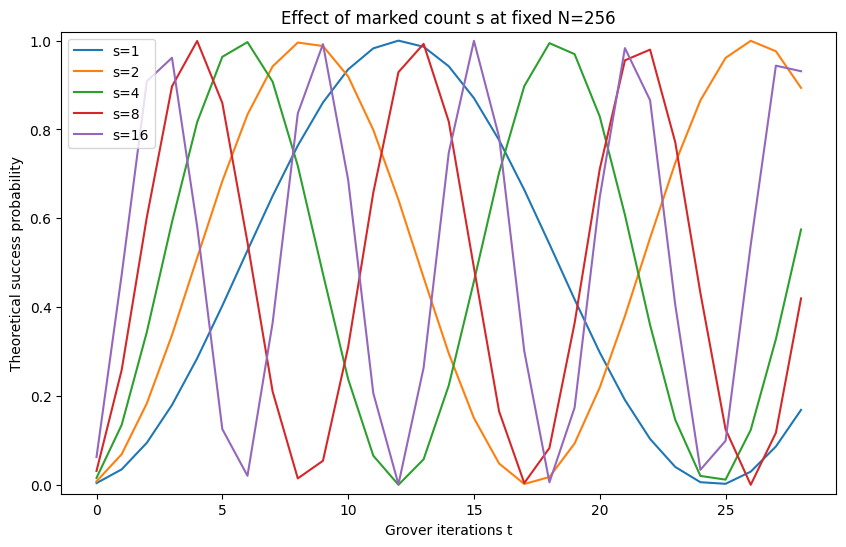

In [13]:
n_fixed = 8
N_fixed = 2 ** n_fixed
s_cases = [1, 2, 4, 8, 16]

largest_peak = max(
    theoretical_best_integer_t(N_fixed, s_case)
    for s_case in s_cases
)

t_values = range(2 * largest_peak + 5)

varying_s_rows = []

for s_case in s_cases:
    for t in t_values:
        varying_s_rows.append({
            "s": s_case,
            "t": t,
            "P_theory": grover_theory_probability(
                N_fixed,
                s_case,
                t,
            ),
        })

varying_s_df = pd.DataFrame(varying_s_rows)

plt.figure(figsize=(10, 6))

for s_case in s_cases:
    subset = varying_s_df[varying_s_df["s"] == s_case]
    plt.plot(
        subset["t"],
        subset["P_theory"],
        label=f"s={s_case}",
    )

plt.xlabel("Grover iterations t")
plt.ylabel("Theoretical success probability")
plt.title(f"Effect of marked count s at fixed N={N_fixed}")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

## 7. Why do the curves change?

Because

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}},
$$

increasing $s$ increases $\theta$.

Each Grover iteration rotates the state by $2\theta$. Therefore

$$
s\uparrow
\Rightarrow
\theta\uparrow
\Rightarrow
2\theta\uparrow
\Rightarrow
t_{\mathrm{peak}}\downarrow.
$$

The number of solutions therefore controls the timescale of amplitude amplification.

In [14]:
peak_rows = []

for s_case in s_cases:
    theta = asin(sqrt(s_case / N_fixed))
    t_continuous = pi / (4 * theta) - 0.5
    t_integer = theoretical_best_integer_t(N_fixed, s_case)

    peak_rows.append({
        "N": N_fixed,
        "s": s_case,
        "theta": theta,
        "continuous_peak_t": t_continuous,
        "best_integer_t": t_integer,
        "peak_probability": grover_theory_probability(
            N_fixed,
            s_case,
            t_integer,
        ),
    })

peak_comparison_df = pd.DataFrame(peak_rows)
peak_comparison_df

,N,s,theta,continuous_peak_t,best_integer_t,peak_probability
0,256,1,0.062541,12.058180,12,0.999947
1,256,2,0.088504,8.374170,8,0.995620
2,256,4,0.125328,5.766750,6,0.996586
3,256,8,0.177711,3.919535,4,0.999182
4,256,16,0.252680,2.608269,3,0.961319


## 8. Overshooting

The probability

$$
P(t)
=
\sin^2((2t+1)\theta)
$$

is oscillatory.

After the state passes the marked direction, further Grover iterations can reduce the success probability.

This is the overshooting phenomenon. The same oscillatory behavior, together with the difficulty it creates when the number of solutions is not known in advance, is central to the multiple solution analysis of Boyer et al. [2].


In [15]:
n_over = 8
N_over = 2 ** n_over
s_over = 1

marked_over = make_marked_states(n_over, s_over)
t_peak = theoretical_best_integer_t(N_over, s_over)

overshoot_rows = []

for t in range(max(0, t_peak - 4), t_peak + 9):
    overshoot_rows.append({
        "t": t,
        "P_theory": grover_theory_probability(
            N_over,
            s_over,
            t,
        ),
        "P_sim": simulation_success_probability(
            n_over,
            marked_over,
            t,
        ),
    })

overshoot_df = pd.DataFrame(overshoot_rows)
overshoot_df

,t,P_theory,P_sim
0,8,0.763722,0.763722
1,9,0.860676,0.860676
2,10,0.935176,0.935176
3,11,0.982583,0.982583
4,12,0.999947,0.999947
5,13,0.986186,0.986186
6,14,0.942157,0.942157
7,15,0.870602,0.870602
8,16,0.775974,0.775974
9,17,0.664165,0.664165


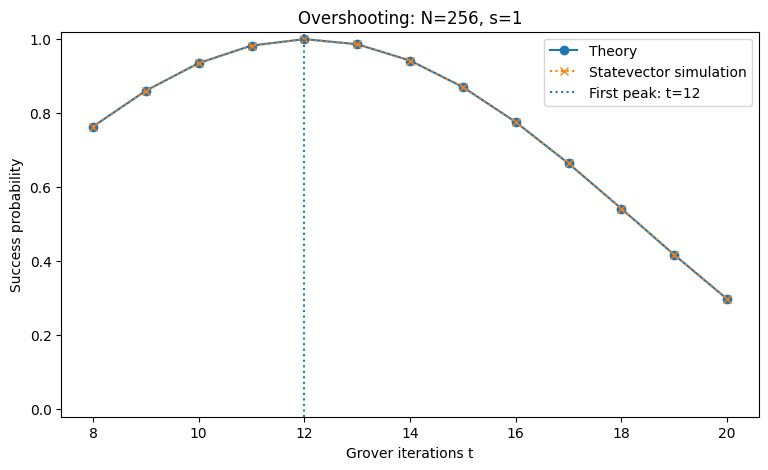

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    overshoot_df["t"],
    overshoot_df["P_theory"],
    marker="o",
    label="Theory",
)

plt.plot(
    overshoot_df["t"],
    overshoot_df["P_sim"],
    marker="x",
    linestyle=":",
    label="Statevector simulation",
)

plt.axvline(
    t_peak,
    linestyle=":",
    label=f"First peak: t={t_peak}",
)

plt.xlabel("Grover iterations t")
plt.ylabel("Success probability")
plt.title(f"Overshooting: N={N_over}, s={s_over}")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.show()

### 8.1 Why does overshooting matter?

The useful stopping point depends on

$$
s
\rightarrow
\theta
\rightarrow
t_{\mathrm{peak}}.
$$

This dependence is more than a shift in the location of the maximum. Because the success probability is oscillatory, choosing too many iterations can undo earlier amplification and move probability back out of the marked subspace.

If $s$ is unknown, then $\theta$ is also unknown. The rotation accumulated per Grover iteration is therefore unknown, so a stopping count cannot in general be matched to the first useful maximum using the standard known $s$ rule. BBHT identifies this as the central difficulty in search when the number of solutions is unknown [2].

This gives the next step of the project a precise target: test what happens when the iteration count is chosen using an estimate $\hat{s}$ rather than the true marked count $s$.


## 9. Results and interpretation

The validation produced near exact agreement between the closed form Grover prediction and the ideal statevector simulation.

For the sanity case

$$
n=5,\qquad N=32,\qquad s=1,
$$

the trajectory reached

$$
P_{\mathrm{theory}}(4)
\approx
P_{\mathrm{sim}}(4)
\approx
0.999182.
$$

Across the full tested trajectory for this case, the maximum absolute difference was approximately

$$
6.38\times10^{-14},
$$

with mean squared error approximately

$$
6.33\times10^{-28}.
$$

The broader sweep showed the same pattern. The remaining differences were at the scale of floating point numerical precision rather than evidence of a meaningful discrepancy between the mathematical model and the simulated unitary dynamics.

The marked label independence test separately checks several different sets with the same $N$ and $s$. After execution, the maximum pairwise trajectory spread and the maximum error against theory quantify whether the total success probability is insensitive to the particular marked labels, as predicted.

The validation sweep also identifies the first simulated local maximum directly from the simulated trajectory. The sampled interval is sized using the theoretical timescale, but the simulated maximum is not selected from candidates restricted to the neighborhood of the theoretical peak.

Therefore, for the tested values of $N$, $s$, and $t$,

$$
\boxed{
P_{\mathrm{sim}}(t)
\approx
P_{\mathrm{theory}}(t)
}
$$

to numerical precision.

### 9.1 First peak versus later recurrences

Because

$$
P(t)=\sin^2((2t+1)\theta),
$$

Grover success probability is periodic. After the first maximum, the probability decreases and later rises again.

A later recurrence can occasionally reach a slightly larger discrete probability than the first recurrence because $t$ is restricted to integer values.

Therefore, when analyzing the useful stopping point, the relevant quantity is the first local maximum rather than the global maximum over an arbitrarily long sampled interval.

This distinction matters because Grover search is concerned with reaching high success probability efficiently, not with waiting for a later recurrence after unnecessary oracle applications.

### 9.2 Integer iteration counts matter

The continuous optimum is

$$
t_{\mathrm{continuous}}
=
\frac{\pi}{4\theta}
-
\frac{1}{2}.
$$

However, Grover iterations are discrete, so $t$ must be an integer.

For example, at

$$
N=256,\qquad s=16,
$$

the continuous optimum is approximately

$$
t_{\mathrm{continuous}}
\approx
2.608,
$$

while the best integer choice is

$$
t=3.
$$

The corresponding peak probability is approximately

$$
0.961319,
$$

rather than exactly $1$.

Thus, even when $s$ is known exactly, the discrete iteration constraint can prevent the algorithm from landing exactly on the continuous optimum.

### 9.3 Overshooting result

For

$$
N=256,\qquad s=1,
$$

the first useful maximum occurs around

$$
t=12,
$$

with success probability approximately

$$
0.999947.
$$

The trajectory directly displays the decline after this first maximum predicted by the oscillatory success law. Within the ideal implementation, this confirms that applying additional Grover iterations does not monotonically improve success.


## 10. Conclusion

The ideal statevector implementation reproduces the theoretical Grover success probability to numerical precision for all tested values of $N$, $s$, and integer $t$, with each tested case satisfying

$$
1\le s<N.
$$

The trivial case $s=N$ is excluded from the two dimensional marked and unmarked decomposition because no unmarked subspace remains.

The result of this notebook is therefore an implementation validation: the implemented Grover circuit reproduces the established ideal unitary dynamics across the tested configurations. It is not an independent experimental validation of Grover theory itself.

Two operational features remain important for the unknown solution count problem. First, the continuous optimum is generally not an integer, so the best realizable success probability can be below one even when $s$ is known exactly. Second, after the first maximum, further Grover iterations can reduce success because the state overshoots the marked direction.

The baseline therefore establishes the operational assumption that will be deliberately violated in Notebook 02: throughout Notebook 01, the iteration count is chosen using the true marked count $s$.

Notebook 02 removes that assumption.

$$
\boxed{
\text{How sensitive is standard Grover search to using an incorrect estimate }\hat{s}\text{?}
}
$$


## References

1. Lov K. Grover, *A fast quantum mechanical algorithm for database search*.
2. Michel Boyer, Gilles Brassard, Peter Høyer, and Alain Tapp, *Tight bounds on quantum searching*.
3. Gilles Brassard, Peter Høyer, Michele Mosca, and Alain Tapp, *Quantum Amplitude Amplification and Estimation*.